# Correlation loss

This notebook scores one measurement: how much the luminance pattern inside a known building changed between a pre-event satellite image and a post-event image. The score is \(1-r\), where \(r\) is the Pearson correlation of the paired pixels. A higher score means the roof pattern changed more.

The correlation is the spatial-pattern measurement in Gonzalez and Woods and in Szeliski, *Computer Vision: Algorithms and Applications*. It is not the template-matching score from Lab 3. Lab 3's normalized cross-correlation is used only to line the post-event patch up with the pre-event patch.

The notebook does not read the other four scores and does not choose weights. Mexico City and Palu are not opened. Damage labels are joined only after the score exists, so the figures and the partial table can be drawn. The score function itself takes two luminance vectors and returns a number.


## Dataset and the shared subset

The xView2 challenge training set is `Dataset/train` next to the project folder that contains this notebook. `XVIEW2_ROOT` overrides that path. Each pair is a pre-event PNG, a post-event PNG, and a post-disaster JSON. Polygons come from `features.xy`: pixel coordinates in the WKT, `uid` as the building id, and `subtype` as the damage label. Unclassified polygons are dropped.

Results for this score are written under `outputs/correlation_loss/progress/`, with `tables/` for the CSV and `figures/` for the plots. `outputs/correlation_loss/final/` is left for the later pass over the remaining practice pairs. The same layout is used by the other scores: `change_vector`, `morphology`, `lab_histogram`, `texture_contrast`, and, once those tables exist, `fusion`.

The 13 pairs below are a practice subset, large enough for a destroyed-versus-rest F1 and an undamaged false-positive rate. Santa Rosa, the Southern California fire, Midwest flooding, and the Guatemala volcano are practice events. Destroyed buildings are concentrated in the fire pairs. The quiet pairs are there so an intact roof can be counted as a false positive. This run is incomplete. It is not the evaluation.


In [1]:
import csv
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


def github_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "correlation_loss.ipynb").is_file():
            return candidate
        nested = candidate / "Github"
        if (nested / "src" / "correlation_loss.ipynb").is_file():
            return nested
    raise FileNotFoundError("correlation_loss.ipynb")


GITHUB = github_root()
if os.environ.get("XVIEW2_ROOT"):
    DATA_ROOT = Path(os.environ["XVIEW2_ROOT"]).resolve()
else:
    DATA_ROOT = (GITHUB.parent / "Dataset" / "train").resolve()
IMAGE_DIR = DATA_ROOT / "images"
LABEL_DIR = DATA_ROOT / "labels"
SCORE_DIR = GITHUB / "outputs" / "correlation_loss"
TABLE_DIR = SCORE_DIR / "progress" / "tables"
FIGURE_DIR = SCORE_DIR / "progress" / "figures"
for folder in (
    TABLE_DIR,
    FIGURE_DIR,
    SCORE_DIR / "final" / "tables",
    SCORE_DIR / "final" / "figures",
):
    folder.mkdir(parents=True, exist_ok=True)

SUBSET = [
    "santa-rosa-wildfire_00000006",
    "santa-rosa-wildfire_00000007",
    "santa-rosa-wildfire_00000011",
    "santa-rosa-wildfire_00000002",
    "socal-fire_00000081",
    "socal-fire_00000082",
    "socal-fire_00000090",
    "socal-fire_00000002",
    "midwest-flooding_00000143",
    "midwest-flooding_00000001",
    "midwest-flooding_00000003",
    "guatemala-volcano_00000025",
    "guatemala-volcano_00000006",
]

if not IMAGE_DIR.is_dir() or not LABEL_DIR.is_dir():
    raise FileNotFoundError(DATA_ROOT)


## Histogram matching

Singh (1989) and Lu et al. (2004) both require the two dates to share an intensity scale before a difference, or a correlation, means a change of the surface. Histogram matching is the point operation that does that. Lab 1 builds a histogram by counting gray levels and a cumulative distribution by `cumsum`. Gonzalez and Woods turn those two cumulative distributions into a lookup table: each post-event gray level is replaced by the pre-event gray level with the same cumulative value. Pratt treats the same table as a point operation \(s = T(r)\).

The match is done independently on the three color channels, with 256 bins. Pixels that are very dark and locally smooth are left out of both histograms, so a large dark water or shadow region does not set the roof scale. The constants used here are provisional and were not chosen on Mexico City or Palu: luminance below 40, and a 5 by 5 local standard deviation below 8. The lookup table is still applied to every pixel. Local standard deviation is the sample spread inside a box window, the same kind of neighborhood statistic used when Lab 1 and the spatial-filtering lectures separate a flat region from a textured one.


In [2]:
def luminance(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def local_std(gray, window=5):
    values = gray.astype(np.float64)
    mean = cv2.blur(values, (window, window))
    second = cv2.blur(values * values, (window, window))
    variance = np.maximum(second - mean * mean, 0.0)
    return np.sqrt(variance)


def usable_pixels(image):
    gray = luminance(image)
    dark = gray < 40
    smooth = local_std(gray) < 8
    return ~(dark & smooth)


def match_channel(source, reference, source_keep, reference_keep):
    source_hist = np.bincount(source[source_keep], minlength=256).astype(np.float64)
    reference_hist = np.bincount(reference[reference_keep], minlength=256).astype(np.float64)
    if source_hist.sum() == 0 or reference_hist.sum() == 0:
        return source.copy()
    source_cdf = np.cumsum(source_hist) / source_hist.sum()
    reference_cdf = np.cumsum(reference_hist) / reference_hist.sum()
    lookup = np.searchsorted(reference_cdf, source_cdf, side="left")
    lookup = np.clip(lookup, 0, 255).astype(np.uint8)
    return lookup[source]


def histogram_match(post, pre):
    source_keep = usable_pixels(post)
    reference_keep = usable_pixels(pre)
    matched = np.empty_like(post)
    for channel in range(3):
        matched[:, :, channel] = match_channel(
            post[:, :, channel],
            pre[:, :, channel],
            source_keep,
            reference_keep,
        )
    return matched


## Local alignment

xBD pairs are already registered, but a roof can still sit a few pixels away from its pre-event footprint because the satellite is off-nadir. The workflow allows a shift of at most 4 pixels, and only when the short side of the polygon is at least 12 pixels. Smaller roofs are left where they are.

The shift is the peak of normalized cross-correlation, which is the template match in Lab 3. For a template \(T\) and a patch \(P\), both with their means removed,

\[
\mathrm{NCC} = \frac{\sum (T-\bar T)(P-\bar P)}{\sqrt{\sum (T-\bar T)^2 \sum (P-\bar P)^2}}.
\]

Lab 3 writes that sum in a loop. Here the search window is only 9 by 9, so `cv2.matchTemplate` with `TM_CCOEFF_NORMED` evaluates the same coefficient. Szeliski's frequency-domain phase correlation is the whole-image reserve and is not used on this subset. A flat template has no peak, and the shift stays zero.


In [3]:
def polygon_points(wkt):
    start = wkt.find("((")
    end = wkt.rfind("))")
    body = wkt[start + 2:end]
    points = []
    for piece in body.split(","):
        parts = piece.split()
        points.append([float(parts[0]), float(parts[1])])
    return np.asarray(points, dtype=np.float64)


def short_side(points):
    width = float(points[:, 0].max() - points[:, 0].min())
    height = float(points[:, 1].max() - points[:, 1].min())
    return min(width, height)


def best_shift(pre_gray, post_gray, points):
    if short_side(points) < 12:
        return 0, 0
    height, width = pre_gray.shape
    x0 = max(0, int(np.floor(points[:, 0].min())))
    y0 = max(0, int(np.floor(points[:, 1].min())))
    x1 = min(width, int(np.ceil(points[:, 0].max())) + 1)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + 1)
    if x1 - x0 < 2 or y1 - y0 < 2:
        return 0, 0
    template = pre_gray[y0:y1, x0:x1]
    if float(template.std()) < 1.0:
        return 0, 0
    search_x0 = max(0, x0 - 4)
    search_y0 = max(0, y0 - 4)
    search_x1 = min(width, x1 + 4)
    search_y1 = min(height, y1 + 4)
    search = post_gray[search_y0:search_y1, search_x0:search_x1]
    if search.shape[0] < template.shape[0] or search.shape[1] < template.shape[1]:
        return 0, 0
    scores = cv2.matchTemplate(search, template, cv2.TM_CCOEFF_NORMED)
    if not np.isfinite(scores).any():
        return 0, 0
    scores = np.nan_to_num(scores, nan=-1.0)
    _, _, _, peak = cv2.minMaxLoc(scores)
    dx = int(np.clip(peak[0] - (x0 - search_x0), -4, 4))
    dy = int(np.clip(peak[1] - (y0 - search_y0), -4, 4))
    return dx, dy


## Polygon interior and the correlation score

The polygon is filled on the image grid, the raster mask from the binary-image lectures, and then eroded by one pixel with a 3 by 3 square. Erosion keeps the roof edge, where the footprint is least reliable, out of the correlation. If fewer than 40 pixels survive, the original polygon is used and the building is still scored.

Inside that mask the score uses luminance only, after the post-event image has been histogram-matched. Let the pre-event samples be \(a_i\) and the aligned post-event samples be \(b_i\). The Pearson correlation is

\[
r = \frac{\sum (a_i-\bar a)(b_i-\bar b)}{\sqrt{\sum (a_i-\bar a)^2 \sum (b_i-\bar b)^2}}.
\]

The reported score is \(1-r\). Because \(r\) lies in \([-1, 1]\), the score lies in \([0, 2]\) and is not clamped to \([0, 1]\). An intact roof stays near 0 after the brightness match. A collapsed or replaced roof moves toward 2.

If either date is nearly flat, the denominator is not a meaningful pattern. The rule from the workflow plan is applied on the 0–255 scale: standard deviation below 1 gray level. Two flat patches score 0. A flat patch paired with a textured one scores 2, the same value as a perfect negative correlation, because the pattern appeared or vanished.


In [4]:
def polygon_mask(points, shape):
    mask = np.zeros(shape, dtype=np.uint8)
    contour = np.round(points).astype(np.int32)
    cv2.fillPoly(mask, [contour], 1)
    return mask


def interior_mask(points, shape):
    mask = polygon_mask(points, shape)
    eroded = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=1)
    if int(eroded.sum()) < 40:
        return mask
    return eroded


def paired_values(pre_gray, post_gray, mask, dx, dy):
    rows, cols = np.nonzero(mask)
    shifted_rows = rows + dy
    shifted_cols = cols + dx
    height, width = pre_gray.shape
    keep = (
        (shifted_rows >= 0)
        & (shifted_rows < height)
        & (shifted_cols >= 0)
        & (shifted_cols < width)
    )
    rows = rows[keep]
    cols = cols[keep]
    shifted_rows = shifted_rows[keep]
    shifted_cols = shifted_cols[keep]
    return pre_gray[rows, cols], post_gray[shifted_rows, shifted_cols]


def correlation_loss(pre_values, post_values):
    pre_values = pre_values.astype(np.float64)
    post_values = post_values.astype(np.float64)
    pre_spread = float(pre_values.std())
    post_spread = float(post_values.std())
    if pre_spread < 1.0 and post_spread < 1.0:
        return 0.0
    if pre_spread < 1.0 or post_spread < 1.0:
        return 2.0
    correlation = np.corrcoef(pre_values, post_values)[0, 1]
    if not np.isfinite(correlation):
        return 2.0
    return float(1.0 - correlation)


## Scoring the subset

Each pair is histogram-matched once. Each classified polygon is then shifted, eroded, and scored on its own. The CSV columns are `image_id`, `building_id`, `score`, and `n_pixels`. `n_pixels` is the number of luminance samples that entered the correlation. The label is stored in memory for the next sections and is not an argument of `correlation_loss`.


In [5]:
def load_pair(image_id):
    pre = cv2.imread(str(IMAGE_DIR / f"{image_id}_pre_disaster.png"), cv2.IMREAD_COLOR)
    post = cv2.imread(str(IMAGE_DIR / f"{image_id}_post_disaster.png"), cv2.IMREAD_COLOR)
    if pre is None or post is None:
        raise FileNotFoundError(image_id)
    label_path = LABEL_DIR / f"{image_id}_post_disaster.json"
    label = json.loads(label_path.read_text())
    return pre, post, label["features"]["xy"]


rows = []
for image_id in SUBSET:
    pre, post, features = load_pair(image_id)
    matched = histogram_match(post, pre)
    pre_gray = luminance(pre)
    post_gray = luminance(matched)
    for feature in features:
        subtype = feature["properties"]["subtype"]
        if subtype == "un-classified":
            continue
        points = polygon_points(feature["wkt"])
        if len(points) < 3:
            continue
        mask = interior_mask(points, pre_gray.shape)
        if int(mask.sum()) == 0:
            continue
        dx, dy = best_shift(pre_gray, post_gray, points)
        pre_values, post_values = paired_values(pre_gray, post_gray, mask, dx, dy)
        if pre_values.size == 0:
            continue
        rows.append({
            "image_id": image_id,
            "building_id": feature["properties"]["uid"],
            "score": correlation_loss(pre_values, post_values),
            "n_pixels": int(pre_values.size),
            "pre_mean": float(pre_values.mean()),
            "subtype": subtype,
            "dx": dx,
            "dy": dy,
            "points": points,
        })

csv_path = TABLE_DIR / "correlation_subset.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=["image_id", "building_id", "score", "n_pixels"])
    writer.writeheader()
    for row in rows:
        writer.writerow({
            "image_id": row["image_id"],
            "building_id": row["building_id"],
            "score": f"{row['score']:.6f}",
            "n_pixels": row["n_pixels"],
        })

print(f"buildings {len(rows)}")
print(f"csv {csv_path.resolve()}")


buildings 878
csv /Users/aliyilmaz/Desktop/Dersler/CS419/Project/Github/outputs/correlation_loss/progress/tables/correlation_subset.csv


## Figures

Each example row is one building. The post-event crop is taken at the shift found for that polygon, so the outline sits on the aligned roof. The third panel is the absolute luminance difference after that shift. It shows the two intensities. The number in the title is \(1-r\), not the mean of the difference.

The destroyed figure uses two buildings from different practice events. The intact figure uses one undamaged roof with a low score and one undamaged roof with a high score, the case where an intact pattern still decorrelates. Buildings used in the panels have a short side of at least 16 pixels.

The charts summarize the same 13 pairs: the score by damage class, the no-damage and destroyed histograms, and the mean score on each practice event. Minor and major damage are scarce here, so those two boxes are descriptive only. Mexico City and Palu are not in these figures.


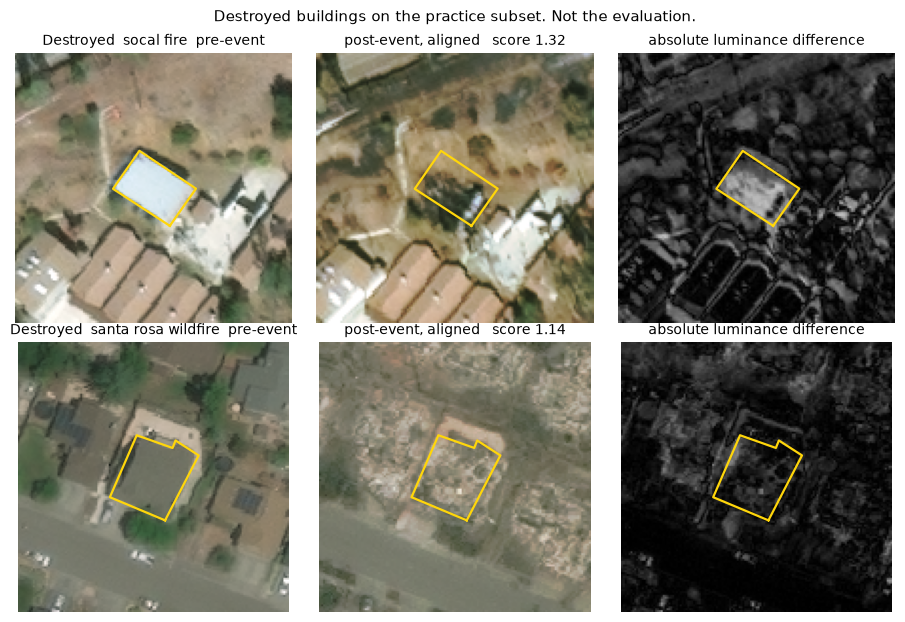

socal-fire_00000090 0ced6b3c-1637-4043-925e-eef5f7362a67 1.322 671
santa-rosa-wildfire_00000007 5f11b5d1-b50b-4ec5-9bb7-ef5d356c39e1 1.135 1121


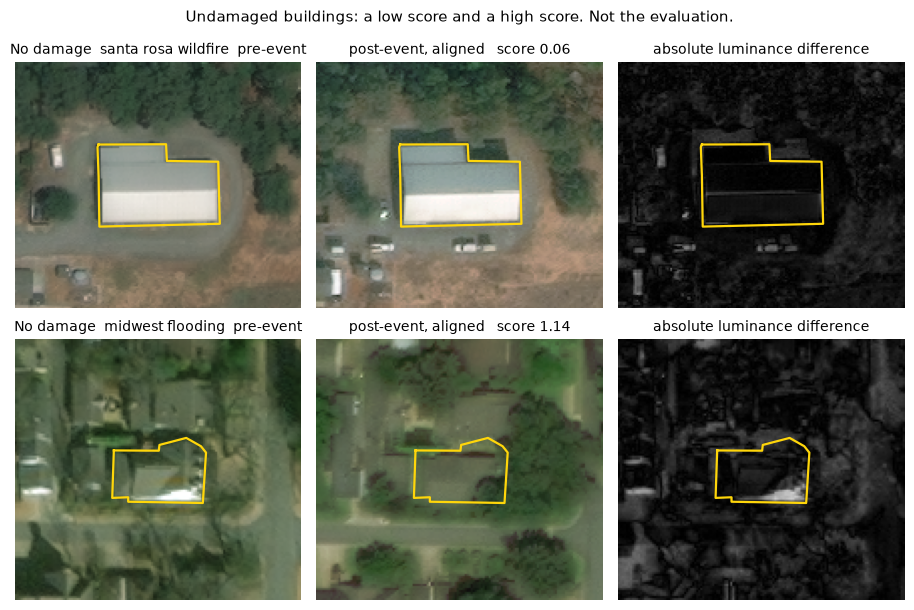

santa-rosa-wildfire_00000002 c6624647-0405-4e45-be0b-b93511295439 0.063 2965
midwest-flooding_00000003 f99a65f9-99d9-4f3d-8709-64981b90aadb 1.145 1150


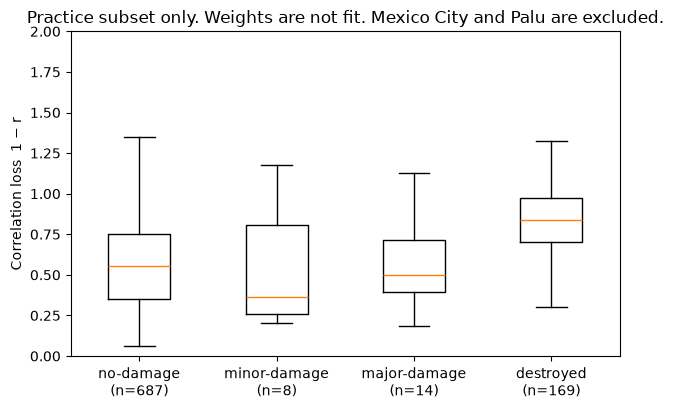

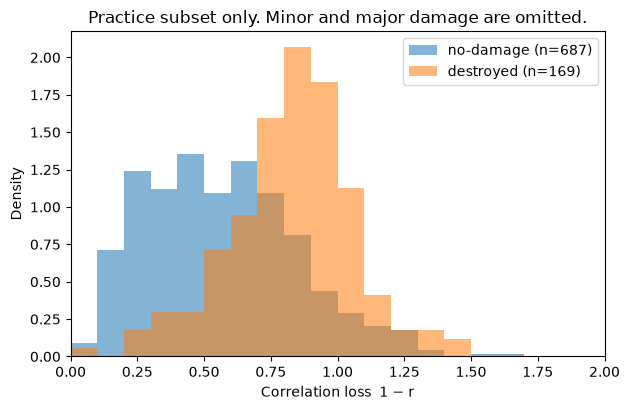

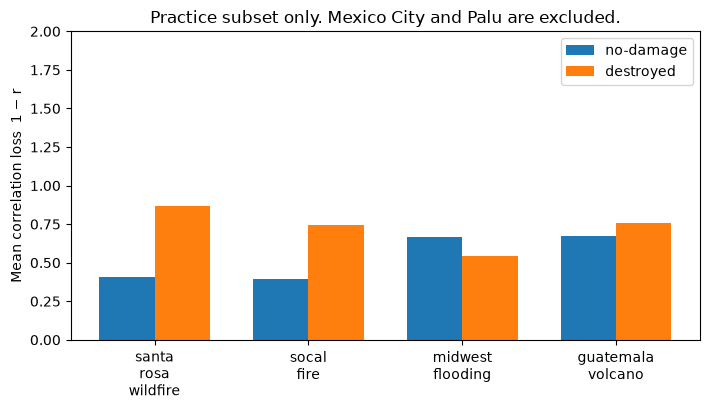

In [6]:
def crop_box(points, shape, margin=48):
    height, width = shape
    x0 = max(0, int(np.floor(points[:, 0].min())) - margin)
    y0 = max(0, int(np.floor(points[:, 1].min())) - margin)
    x1 = min(width, int(np.ceil(points[:, 0].max())) + margin)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + margin)
    return x0, y0, x1, y1


def take_crop(image, box, dx=0, dy=0):
    x0, y0, x1, y1 = box
    height, width = image.shape[:2]
    src_x0 = min(max(x0 + dx, 0), width - 1)
    src_y0 = min(max(y0 + dy, 0), height - 1)
    src_x1 = min(max(x1 + dx, src_x0 + 1), width)
    src_y1 = min(max(y1 + dy, src_y0 + 1), height)
    crop = image[src_y0:src_y1, src_x0:src_x1]
    canvas = np.zeros((y1 - y0, x1 - x0) + image.shape[2:], dtype=image.dtype)
    dest_x = src_x0 - (x0 + dx)
    dest_y = src_y0 - (y0 + dy)
    canvas[dest_y:dest_y + crop.shape[0], dest_x:dest_x + crop.shape[1]] = crop
    return canvas


def draw_outline(axis, points, origin):
    relative = points - np.array(origin, dtype=np.float64)
    closed = np.vstack([relative, relative[:1]])
    axis.plot(closed[:, 0], closed[:, 1], color="#ffd60a", linewidth=1.6)
    axis.set_axis_off()


def show_case(axis, image, points, origin, title):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    draw_outline(axis, points, origin)
    axis.set_title(title, fontsize=10)


def event_name(image_id):
    return image_id.rsplit("_", 1)[0]


def panel_cases(cases, path, suptitle):
    fig, axes = plt.subplots(len(cases), 3, figsize=(9.2, 3.15 * len(cases)))
    if len(cases) == 1:
        axes = np.array([axes])
    cache = {}
    for axis_row, case in zip(axes, cases):
        if case["image_id"] not in cache:
            pre, post, _ = load_pair(case["image_id"])
            cache[case["image_id"]] = (pre, histogram_match(post, pre))
        pre, matched = cache[case["image_id"]]
        box = crop_box(case["points"], pre.shape[:2])
        pre_crop = take_crop(pre, box)
        post_crop = take_crop(matched, box, case["dx"], case["dy"])
        difference = np.clip(
            np.abs(luminance(pre_crop).astype(np.int16) - luminance(post_crop).astype(np.int16)),
            0,
            255,
        ).astype(np.uint8)
        difference_bgr = cv2.cvtColor(difference, cv2.COLOR_GRAY2BGR)
        origin = (box[0], box[1])
        place = event_name(case["image_id"]).replace("-", " ")
        kind = "Destroyed" if case["subtype"] == "destroyed" else "No damage"
        show_case(axis_row[0], pre_crop, case["points"], origin, f"{kind}  {place}  pre-event")
        show_case(
            axis_row[1],
            post_crop,
            case["points"],
            origin,
            f"post-event, aligned   score {case['score']:.2f}",
        )
        show_case(axis_row[2], difference_bgr, case["points"], origin, "absolute luminance difference")
    fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    for case in cases:
        print(case["image_id"], case["building_id"], f"{case['score']:.3f}", case["n_pixels"])


def visible_cases(subtype):
    pool = []
    for row in rows:
        if row["subtype"] != subtype or row["score"] >= 1.99 or row["n_pixels"] < 250:
            continue
        points = row["points"]
        width = float(points[:, 0].max() - points[:, 0].min())
        height = float(points[:, 1].max() - points[:, 1].min())
        short = min(width, height)
        long = max(width, height)
        if short < 24 or long > 160 or long / short > 2.4:
            continue
        if points[:, 0].min() < 20 or points[:, 1].min() < 20:
            continue
        if points[:, 0].max() > 1004 or points[:, 1].max() > 1004:
            continue
        pool.append(row)
    return sorted(pool, key=lambda row: row["score"])


destroyed_pool = visible_cases("destroyed")
intact_pool = visible_cases("no-damage")
destroyed_high = destroyed_pool[-1]
destroyed_other = next(
    row for row in reversed(destroyed_pool)
    if event_name(row["image_id"]) != event_name(destroyed_high["image_id"])
)
panel_cases(
    [destroyed_high, destroyed_other],
    FIGURE_DIR / "examples_destroyed.png",
    "Destroyed buildings on the practice subset. Not the evaluation.",
)
bright_intact = [row for row in intact_pool if row["pre_mean"] >= 90]
panel_cases(
    [intact_pool[0], (bright_intact or intact_pool)[-1]],
    FIGURE_DIR / "examples_intact.png",
    "Undamaged buildings: a low score and a high score. Not the evaluation.",
)

class_order = ["no-damage", "minor-damage", "major-damage", "destroyed"]
class_scores = [
    [row["score"] for row in rows if row["subtype"] == name]
    for name in class_order
]
fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.boxplot(class_scores, showfliers=False)
axis.set_xticks(
    range(1, len(class_order) + 1),
    [f"{name}\n(n={len(values)})" for name, values in zip(class_order, class_scores)],
)
axis.set_ylabel("Correlation loss  1 − r")
axis.set_ylim(0, 2)
axis.set_title("Practice subset only. Weights are not fit. Mexico City and Palu are excluded.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

bins = np.linspace(0, 2, 21)
fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.hist(class_scores[0], bins=bins, density=True, alpha=0.55, label=f"no-damage (n={len(class_scores[0])})")
axis.hist(class_scores[3], bins=bins, density=True, alpha=0.55, label=f"destroyed (n={len(class_scores[3])})")
axis.set_xlabel("Correlation loss  1 − r")
axis.set_ylabel("Density")
axis.set_xlim(0, 2)
axis.legend()
axis.set_title("Practice subset only. Minor and major damage are omitted.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

event_order = []
for image_id in SUBSET:
    event = event_name(image_id)
    if event not in event_order:
        event_order.append(event)
grouped = {}
for name in ("no-damage", "destroyed"):
    grouped[name] = []
    for event in event_order:
        values = np.array([
            row["score"]
            for row in rows
            if row["subtype"] == name and event_name(row["image_id"]) == event
        ])
        grouped[name].append(float(values.mean()) if values.size else np.nan)
positions = np.arange(len(event_order))
width = 0.36
fig, axis = plt.subplots(figsize=(7.2, 4.2))
axis.bar(positions - width / 2, grouped["no-damage"], width, label="no-damage")
axis.bar(positions + width / 2, grouped["destroyed"], width, label="destroyed")
axis.set_xticks(positions, [event.replace("-", "\n") for event in event_order])
axis.set_ylim(0, 2)
axis.set_ylabel("Mean correlation loss  1 − r")
axis.legend()
axis.set_title("Practice subset only. Mexico City and Palu are excluded.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_event.png", dpi=160, bbox_inches="tight")
plt.show()


## Partial numbers

A single threshold on \(1-r\) turns the score into a destroyed-versus-rest decision. The threshold is the value in \(\{0, 0.01, \ldots, 2\}\) with the highest destroyed-versus-rest F1 among those that keep the undamaged false-positive rate at or below 0.25. A false positive here is an undamaged building whose score is at least the threshold. The same cap is the one used later, when the five scores are weighted. This cut is provisional. It was fit on these 13 pairs only, and it will not be reused on Mexico City or Palu.

Precision, recall, and F1 use destroyed as the positive class and every other classified building as the negative class. Minor damage is too rare in this subset to support its own score. The threshold figure shows F1 and the undamaged false-positive rate across the whole range, with this cut marked.


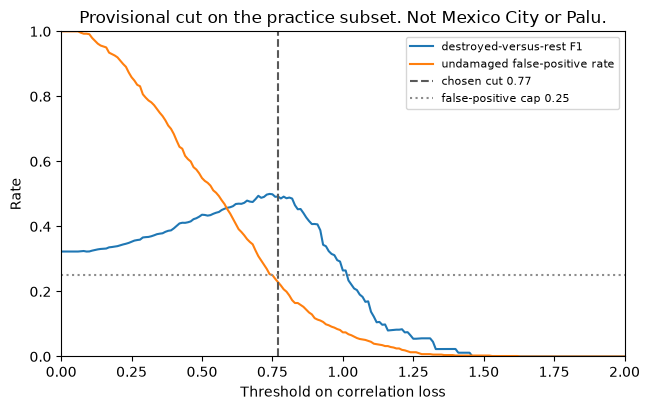

class, n, mean, median
no-damage, 687, 0.5663, 0.5541
minor-damage, 8, 0.5575, 0.3633
major-damage, 14, 0.5724, 0.4993
destroyed, 169, 0.8245, 0.8382
event, no-damage n, no-damage mean, destroyed n, destroyed mean
santa-rosa-wildfire, 208, 0.4083, 116, 0.8694
socal-fire, 61, 0.3914, 26, 0.7451
midwest-flooding, 321, 0.6693, 6, 0.5420
guatemala-volcano, 97, 0.6739, 21, 0.7552
threshold, 0.77, destroyed_f1, 0.4920, precision, 0.4000, recall, 0.6391
undamaged_false_positive_rate, 0.2285, tp, 108, fp, 162, fn, 61
subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.


In [7]:
def binary_counts(y_true, y_pred):
    true_pos = int(np.sum(y_true & y_pred))
    false_pos = int(np.sum(~y_true & y_pred))
    false_neg = int(np.sum(y_true & ~y_pred))
    return true_pos, false_pos, false_neg


def f1_from_counts(true_pos, false_pos, false_neg):
    precision = true_pos / (true_pos + false_pos) if true_pos + false_pos else 0.0
    recall = true_pos / (true_pos + false_neg) if true_pos + false_neg else 0.0
    if precision + recall == 0:
        return 0.0, precision, recall
    return 2 * precision * recall / (precision + recall), precision, recall


scores = np.array([row["score"] for row in rows], dtype=np.float64)
destroyed = np.array([row["subtype"] == "destroyed" for row in rows])
undamaged = np.array([row["subtype"] == "no-damage" for row in rows])
thresholds = np.round(np.arange(0.0, 2.001, 0.01), 2)
f1_curve = []
rate_curve = []
best = None
for cut in thresholds:
    predicted = scores >= cut
    undamaged_rate = float(predicted[undamaged].mean()) if undamaged.any() else 1.0
    true_pos, false_pos, false_neg = binary_counts(destroyed, predicted)
    f1_value, precision, recall = f1_from_counts(true_pos, false_pos, false_neg)
    f1_curve.append(f1_value)
    rate_curve.append(undamaged_rate)
    if undamaged_rate > 0.25:
        continue
    candidate = (f1_value, -undamaged_rate, cut, precision, recall, undamaged_rate, true_pos, false_pos, false_neg)
    if best is None or candidate > best:
        best = candidate

f1, _, threshold, precision, recall, undamaged_rate, true_pos, false_pos, false_neg = best

fig, axis = plt.subplots(figsize=(6.6, 4.2))
axis.plot(thresholds, f1_curve, label="destroyed-versus-rest F1")
axis.plot(thresholds, rate_curve, label="undamaged false-positive rate")
axis.axvline(threshold, color="0.35", linestyle="--", label=f"chosen cut {threshold:.2f}")
axis.axhline(0.25, color="0.55", linestyle=":", label="false-positive cap 0.25")
axis.set_xlim(0, 2)
axis.set_ylim(0, 1)
axis.set_xlabel("Threshold on correlation loss")
axis.set_ylabel("Rate")
axis.legend(fontsize=8)
axis.set_title("Provisional cut on the practice subset. Not Mexico City or Palu.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "threshold_curve.png", dpi=160, bbox_inches="tight")
plt.show()

lines = ["class, n, mean, median"]
for name in class_order:
    values = scores[np.array([row["subtype"] == name for row in rows])]
    if values.size == 0:
        lines.append(f"{name}, 0, , ")
        continue
    lines.append(f"{name}, {values.size}, {values.mean():.4f}, {np.median(values):.4f}")
lines.append("event, no-damage n, no-damage mean, destroyed n, destroyed mean")
for event in event_order:
    no_damage_values = [
        row["score"] for row in rows
        if row["subtype"] == "no-damage" and event_name(row["image_id"]) == event
    ]
    destroyed_values = [
        row["score"] for row in rows
        if row["subtype"] == "destroyed" and event_name(row["image_id"]) == event
    ]
    no_mean = f"{np.mean(no_damage_values):.4f}" if no_damage_values else ""
    destroyed_mean = f"{np.mean(destroyed_values):.4f}" if destroyed_values else ""
    lines.append(
        f"{event}, {len(no_damage_values)}, {no_mean}, {len(destroyed_values)}, {destroyed_mean}"
    )
lines.append(
    f"threshold, {threshold:.2f}, destroyed_f1, {f1:.4f}, precision, {precision:.4f}, recall, {recall:.4f}"
)
lines.append(
    f"undamaged_false_positive_rate, {undamaged_rate:.4f}, tp, {true_pos}, fp, {false_pos}, fn, {false_neg}"
)
lines.append("subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.")
metrics_path = TABLE_DIR / "correlation_metrics.txt"
metrics_path.write_text("\n".join(lines) + "\n")
print("\n".join(lines))


## What this run is, and what is left

The CSV, the example panels, and the charts are the progress material for correlation loss. They live under `outputs/correlation_loss/progress/`. The class means should be read with the subset in mind: most destroyed buildings here are fire losses, and minor damage has only a handful of polygons.

Still open for this score: the same CSV on the remaining practice pairs, written later under `outputs/correlation_loss/final/`. After the other four score tables exist, the open steps are z-scores and nonnegative weights on the fit split, the holdout check, and one pass on Mexico City and Palu. Those cities are not in `SUBSET`, and nothing in this notebook is a reason to change the formula after they are seen.
